# Bahdanau 注意力
:label:`sec_seq2seq_attention`

 :numref:`sec_seq2seq`中探讨了机器翻译问题：
通过设计一个基于两个循环神经网络的编码器-解码器架构，
用于序列到序列学习。
具体来说，循环神经网络编码器将长度可变的序列转换为固定形状的上下文变量，
然后循环神经网络解码器根据生成的词元和上下文变量
按词元生成输出（目标）序列词元。
然而，即使并非所有输入（源）词元都对解码某个词元都有用，
在每个解码步骤中仍使用编码*相同*的上下文变量。
有什么方法能改变上下文变量呢？

我们试着从 :cite:`Graves.2013`中找到灵感：
在为给定文本序列生成手写的挑战中，
Graves设计了一种可微注意力模型，
将文本字符与更长的笔迹对齐，
其中对齐方式仅向一个方向移动。
受学习对齐想法的启发，Bahdanau等人提出了一个没有严格单向对齐限制的
可微注意力模型 :cite:`Bahdanau.Cho.Bengio.2014`。
在预测词元时，如果不是所有输入词元都相关，模型将仅对齐（或参与）输入序列中与当前预测相关的部分。这是通过将上下文变量视为注意力集中的输出来实现的。

## 模型

下面描述的Bahdanau注意力模型
将遵循 :numref:`sec_seq2seq`中的相同符号表达。
这个新的基于注意力的模型与 :numref:`sec_seq2seq`中的模型相同，
只不过 :eqref:`eq_seq2seq_s_t`中的上下文变量$\mathbf{c}$
在任何解码时间步$t'$都会被$\mathbf{c}_{t'}$替换。
假设输入序列中有$T$个词元，
解码时间步$t'$的上下文变量是注意力集中的输出：

$$\mathbf{c}_{t'} = \sum_{t=1}^T \alpha(\mathbf{s}_{t' - 1}, \mathbf{h}_t) \mathbf{h}_t,$$

其中，时间步$t' - 1$时的解码器隐状态$\mathbf{s}_{t' - 1}$是查询，
编码器隐状态$\mathbf{h}_t$既是键，也是值，
注意力权重$\alpha$是使用 :eqref:`eq_attn-scoring-alpha`
所定义的加性注意力打分函数计算的。

与 :numref:`fig_seq2seq_details`中的循环神经网络编码器-解码器架构略有不同，
 :numref:`fig_s2s_attention_details`描述了Bahdanau注意力的架构。

![一个带有Bahdanau注意力的循环神经网络编码器-解码器模型](../img/seq2seq-attention-details.svg)
:label:`fig_s2s_attention_details`


In [6]:
import torch
from torch import nn
from d2l import torch as d2l
import inspect

print(inspect.signature(d2l.AdditiveAttention))

(num_hiddens, dropout, **kwargs)


## 定义注意力解码器

下面看看如何定义Bahdanau注意力，实现循环神经网络编码器-解码器。
其实，我们只需重新定义解码器即可。
为了更方便地显示学习的注意力权重，
以下`AttentionDecoder`类定义了[**带有注意力机制解码器的基本接口**]。


In [2]:
#@save
class AttentionDecoder(d2l.Decoder):
    """带有注意力机制解码器的基本接口"""
    def __init__(self, **kwargs):
        super(AttentionDecoder, self).__init__(**kwargs)

    @property
    def attention_weights(self):
        raise NotImplementedError

接下来，让我们在接下来的`Seq2SeqAttentionDecoder`类中
[**实现带有Bahdanau注意力的循环神经网络解码器**]。
首先，初始化解码器的状态，需要下面的输入：

1. 编码器在所有时间步的最终层隐状态，将作为注意力的键和值；
1. 上一时间步的编码器全层隐状态，将作为初始化解码器的隐状态；
1. 编码器有效长度（排除在注意力池中填充词元）。

在每个解码时间步骤中，解码器上一个时间步的最终层隐状态将用作查询。
因此，注意力输出和输入嵌入都连结为循环神经网络解码器的输入。


In [14]:
#@save
def masked_softmax(X, valid_lens):
    """在最后一个维度上执行带掩蔽的Softmax"""
    if valid_lens is None:
        return nn.functional.softmax(X, dim=-1)
    else:
        shape = X.shape

        if valid_lens.dim() == 1:
            # 将有效长度复制到每个查询
            valid_lens = torch.repeat_interleave(valid_lens, shape[1])
        else:
            valid_lens = valid_lens.reshape(-1)

        # 将无效位置设置为极小值
        X = d2l.sequence_mask(
            X.reshape(-1, shape[-1]),
            valid_lens,
            value=-1e6
        )

        # 恢复形状并计算Softmax
        return nn.functional.softmax(X.reshape(shape), dim=-1)

In [18]:
class AdditiveAttention(nn.Module):
    """加性注意力机制"""
    def __init__(self, key_size, query_size, num_hiddens, dropout):
        super().__init__()
        self.W_k = nn.Linear(key_size, num_hiddens, bias=False)
        self.W_q = nn.Linear(query_size, num_hiddens, bias=False)
        self.w_v = nn.Linear(num_hiddens, 1, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, queries, keys, values, valid_lens):
        queries = self.W_q(queries)
        keys = self.W_k(keys)

        # 计算查询与键的匹配分数
        features = torch.tanh(
            queries.unsqueeze(2) + keys.unsqueeze(1))
        scores = self.w_v(features).squeeze(-1)

        # 掩蔽无效位置并计算注意力权重
        self.attention_weights = masked_softmax(scores, valid_lens)

        # 对值进行加权求和
        return torch.bmm(
            self.dropout(self.attention_weights), values)

In [19]:
class Seq2SeqAttentionDecoder(AttentionDecoder):
    """带加性注意力机制的Seq2Seq解码器"""

    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers,
                 dropout=0, **kwargs):
        super(Seq2SeqAttentionDecoder, self).__init__(**kwargs)

        # 加性注意力：根据Query和Key计算权重，对Value加权求和
        self.attention = AdditiveAttention(
            num_hiddens, num_hiddens, num_hiddens, dropout)

        self.embedding = nn.Embedding(vocab_size, embed_size)  # 词嵌入层
        self.rnn = nn.GRU(
            embed_size + num_hiddens, num_hiddens, num_layers,
            dropout=dropout)  # GRU解码器，输入包含词向量和上下文
        self.dense = nn.Linear(num_hiddens, vocab_size)  # 输出词表预测分数

    def init_state(self, enc_outputs, enc_valid_lens, *args):
        """初始化解码器状态"""
        outputs, hidden_state = enc_outputs
        # 编码器输出：(batch_size, num_steps, num_hiddens)
        # 隐藏状态：(num_layers, batch_size, num_hiddens)
        return (outputs.permute(1, 0, 2), hidden_state, enc_valid_lens)

    def forward(self, X, state):
        """执行解码器前向传播"""
        enc_outputs, hidden_state, enc_valid_lens = state

        # 词嵌入并调整维度：(num_steps, batch_size, embed_size)
        X = self.embedding(X).permute(1, 0, 2)

        outputs, self._attention_weights = [], []

        for x in X:  # 逐时间步解码
            # 使用解码器最后一层隐藏状态作为Query
            query = torch.unsqueeze(hidden_state[-1], dim=1)

            # 使用编码器输出作为Key和Value，计算上下文向量
            context = self.attention(
                query, enc_outputs, enc_outputs, enc_valid_lens)

            # 拼接当前词向量和注意力上下文
            x = torch.cat((context, torch.unsqueeze(x, dim=1)), dim=-1)

            # 输入GRU，更新解码器隐藏状态
            out, hidden_state = self.rnn(x.permute(1, 0, 2), hidden_state)

            outputs.append(out)  # 保存当前时间步输出
            self._attention_weights.append(
                self.attention.attention_weights)  # 保存注意力权重

        # 拼接所有时间步输出，映射到词表维度
        outputs = self.dense(torch.cat(outputs, dim=0))

        # 返回预测结果和更新后的解码器状态
        return outputs.permute(1, 0, 2), [
            enc_outputs, hidden_state, enc_valid_lens]

    @property
    def attention_weights(self):
        return self._attention_weights  # 获取各时间步的注意力权重

接下来，使用包含7个时间步的4个序列输入的小批量[**测试Bahdanau注意力解码器**]。


In [20]:
encoder = d2l.Seq2SeqEncoder(
    vocab_size=10, embed_size=8, num_hiddens=16, num_layers=2)
encoder.eval()

decoder = Seq2SeqAttentionDecoder(
    vocab_size=10, embed_size=8, num_hiddens=16, num_layers=2)
decoder.eval()

X = torch.zeros((4, 7), dtype=torch.long)
state = decoder.init_state(encoder(X), None)
output, state = decoder(X, state)

output.shape, len(state), state[0].shape, len(state[1]), state[1][0].shape

(torch.Size([4, 7, 10]), 3, torch.Size([4, 7, 16]), 2, torch.Size([4, 16]))

## [**训练**]

与 :numref:`sec_seq2seq_training`类似，
我们在这里指定超参数，实例化一个带有Bahdanau注意力的编码器和解码器，
并对这个模型进行机器翻译训练。
由于新增的注意力机制，训练要比没有注意力机制的
 :numref:`sec_seq2seq_training`慢得多。


In [25]:
from torch import nn

class EncoderDecoder(nn.Module):
    """编码器-解码器：兼容D2L训练函数"""

    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, enc_X, dec_X, *args):
        # 编码器处理输入序列
        enc_outputs = self.encoder(enc_X, *args)

        # 初始化解码器状态
        dec_state = self.decoder.init_state(enc_outputs, *args)

        # 返回预测结果和解码器状态
        return self.decoder(dec_X, dec_state)

loss 0.329, 4127.1 tokens/sec on cuda:0


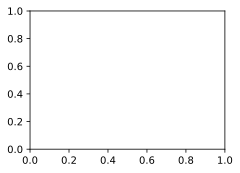

In [26]:
# 创建新的编码器和解码器
encoder = d2l.Seq2SeqEncoder(
    len(src_vocab), embed_size, num_hiddens, num_layers, dropout)

decoder = Seq2SeqAttentionDecoder(
    len(tgt_vocab), embed_size, num_hiddens, num_layers, dropout)

# 使用自定义EncoderDecoder
net = EncoderDecoder(encoder, decoder)

# 先训练2轮验证
d2l.train_seq2seq(
    net, train_iter, lr, 2, tgt_vocab, device
)

loss 0.020, 6611.6 tokens/sec on cuda:0


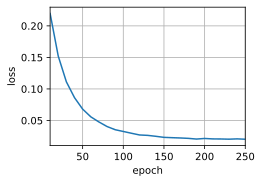

In [28]:
# 设置模型超参数
embed_size, num_hiddens, num_layers, dropout = 32, 32, 2, 0.1
# 词嵌入维度32、隐藏单元数32、GRU层数2、Dropout比例0.1

batch_size, num_steps = 64, 10  # 批量大小64，序列长度10
lr, num_epochs, device = 0.005, 250, d2l.try_gpu()  # 学习率、训练轮数、设备

# 加载机器翻译数据集，获取数据迭代器和源/目标词表
train_iter, src_vocab, tgt_vocab = d2l.load_data_nmt(batch_size, num_steps)

# 创建Seq2Seq编码器
encoder = d2l.Seq2SeqEncoder(
    len(src_vocab), embed_size, num_hiddens, num_layers, dropout)

# 创建带Bahdanau注意力机制的解码器
decoder = Seq2SeqAttentionDecoder(
    len(tgt_vocab), embed_size, num_hiddens, num_layers, dropout)

# 组合编码器和解码器
# net = d2l.EncoderDecoder(encoder, decoder)
net = EncoderDecoder(encoder, decoder)

# 训练机器翻译模型
d2l.train_seq2seq(net, train_iter, lr, num_epochs, tgt_vocab, device)

模型训练后，我们用它[**将几个英语句子翻译成法语**]并计算它们的BLEU分数。


In [29]:
# 定义英文测试句子及对应的法语参考翻译
engs = ['go .', "i lost .", 'he\'s calm .', 'i\'m home .']
fras = ['va !', 'j\'ai perdu .', 'il est calme .', 'je suis chez moi .']

# 遍历每组英文和法语句子
for eng, fra in zip(engs, fras):
    # 使用训练好的Seq2Seq注意力模型进行翻译
    translation, dec_attention_weight_seq = d2l.predict_seq2seq(
        net, eng, src_vocab, tgt_vocab, num_steps, device, True)

    # 输出翻译结果和BLEU评分
    print(f'{eng} => {translation}, ',
          f'bleu {d2l.bleu(translation, fra, k=2):.3f}')

go . => va !,  bleu 1.000
i lost . => j'ai perdu .,  bleu 1.000
he's calm . => joignez-vous à nous .,  bleu 0.000
i'm home . => je suis chez moi .,  bleu 1.000


In [30]:
# 提取解码器每个时间步的注意力权重，并拼接成一个张量
attention_weights = torch.cat(
    [step[0][0][0] for step in dec_attention_weight_seq], 0
).reshape((1, 1, -1, num_steps))  # 转换为4维，方便绘制注意力热图

训练结束后，下面通过[**可视化注意力权重**]
会发现，每个查询都会在键值对上分配不同的权重，这说明
在每个解码步中，输入序列的不同部分被选择性地聚集在注意力池中。


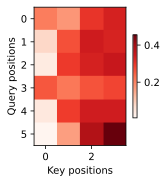

In [31]:
# 绘制Bahdanau注意力权重热图
d2l.show_heatmaps(
    # 截取有效的源语言位置，包括序列结束词元<EOS>
    attention_weights[:, :, :, :len(engs[-1].split()) + 1].cpu(),
    xlabel='Key positions',    # 横轴：源语言词元位置（Key）
    ylabel='Query positions')  # 纵轴：目标语言词元位置（Query）

## 小结

* 在预测词元时，如果不是所有输入词元都是相关的，那么具有Bahdanau注意力的循环神经网络编码器-解码器会有选择地统计输入序列的不同部分。这是通过将上下文变量视为加性注意力池化的输出来实现的。
* 在循环神经网络编码器-解码器中，Bahdanau注意力将上一时间步的解码器隐状态视为查询，在所有时间步的编码器隐状态同时视为键和值。